In [2]:
import pandas as pd
import re
import matplotlib.pyplot as plt
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

In [3]:
# 1. Read WhatsApp chat file
with open("Mentor.txt.txt", "r", encoding="utf-8") as file:
    chat_text = file.read()

In [4]:
# 2. Extract Date, Time, Sender, and Message
pattern = r'^\[(.*?), (.*?)\] (.*?): (.*)$'

messages = []
current = None

for line in chat_text.splitlines():
    match = re.match(pattern, line)

    if match:
        if current:
            messages.append(current)

        current = {
            "Date": match.group(1),
            "Time": match.group(2),
            "Sender": match.group(3),
            "Message": match.group(4)
        }

    elif current:
        current["Message"] += "\n" + line

if current:
    messages.append(current)

In [5]:
# 3. Convert into a DataFrame
chat_df = pd.DataFrame(messages)

In [6]:
# 4. Basic preprocessing
chat_df["Message"] = chat_df["Message"].str.strip()

In [7]:
# Remove empty messages
chat_df = chat_df[chat_df["Message"] != ""]

In [8]:
# Remove messages containing only media placeholders
media_pattern = (
    r"<(image|video|audio|voice message|sticker|gif|document) omitted>"
)

chat_df = chat_df[
    ~chat_df["Message"].str.fullmatch(media_pattern, case=False)
].copy()

In [9]:
# 5. Display the cleaned table
display(chat_df[["Date", "Time", "Sender", "Message"]])

,Date,Time,Sender,Message
0,11/10/25,6:50:16 AM,Logeshwarai Tutor Hope Ai Coimbatore,"Hi LOKESHWARAN R,\n\nI hope your learning jour..."
1,11/10/25,8:47:00 AM,You,"“Yes ma’am, I’m currently watching videos abou..."
2,11/10/25,10:11:20 AM,Logeshwarai Tutor Hope Ai Coimbatore,Okay Sir
3,11/11/25,11:27:00 AM,Logeshwarai Tutor Hope Ai Coimbatore,Hi
5,11/11/25,11:27:40 AM,Logeshwarai Tutor Hope Ai Coimbatore,.ipynb
...,...,...,...,...
1527,10/12/26,8:03:27 AM,You,https://github.com/LokeshDataScienceAI/Week-13...
1528,10/12/26,8:04:04 AM,You,In this link for TF-IDF
1529,10/12/26,8:04:17 AM,You,https://github.com/LokeshDataScienceAI/Week-13...
1530,10/12/26,8:04:57 AM,You,In this link for Hashing vectorizer


In [10]:
# 6. Save CSV and Excel files
base_name = "My mentor conversation chat preprocessing"

chat_df.to_csv(
    base_name + ".csv",
    index=False,
    encoding="utf-8-sig"
)

chat_df.to_excel(
    base_name + ".xlsx",
    index=False
)

In [11]:
# 1. Initialize sentiment analyzer
analyzer = SentimentIntensityAnalyzer()

In [12]:
# 2. Copy preprocessed WhatsApp chat
sentiment_df = chat_df[
    ["Date", "Time", "Sender", "Message"]
].copy()

In [13]:
# 3. Calculate sentiment score
sentiment_df["Compound_Score"] = sentiment_df["Message"].apply(
    lambda message: analyzer.polarity_scores(str(message))["compound"]
)

In [14]:
# 4. Classify sentiment
def classify_sentiment(score):
    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    else:
        return "Neutral"

sentiment_df["Sentiment"] = sentiment_df["Compound_Score"].apply(
    classify_sentiment
)

In [15]:
# 5. Display results
display(sentiment_df.head(10))

,Date,Time,Sender,Message,Compound_Score,Sentiment
0,11/10/25,6:50:16 AM,Logeshwarai Tutor Hope Ai Coimbatore,"Hi LOKESHWARAN R,\n\nI hope your learning jour...",0.9440,Positive
1,11/10/25,8:47:00 AM,You,"“Yes ma’am, I’m currently watching videos abou...",-0.5242,Negative
2,11/10/25,10:11:20 AM,Logeshwarai Tutor Hope Ai Coimbatore,Okay Sir,0.2263,Positive
3,11/11/25,11:27:00 AM,Logeshwarai Tutor Hope Ai Coimbatore,Hi,0.0000,Neutral
5,11/11/25,11:27:40 AM,Logeshwarai Tutor Hope Ai Coimbatore,.ipynb,0.0000,Neutral
6,11/11/25,11:32:58 AM,You,<image omitted> How to delete this already upl...,0.0000,Neutral
8,11/11/25,11:35:37 AM,Logeshwarai Tutor Hope Ai Coimbatore,<image omitted> 3 dots,0.0000,Neutral
10,11/11/25,11:42:26 AM,Logeshwarai Tutor Hope Ai Coimbatore,Commit changes,0.2960,Positive
11,11/11/25,11:43:03 AM,You,Next which option choose,0.0000,Neutral
12,11/11/25,11:43:15 AM,Logeshwarai Tutor Hope Ai Coimbatore,.,0.0000,Neutral


In [16]:
# 6. Count sentiments
print(sentiment_df["Sentiment"].value_counts())

Sentiment
Positive    610
Neutral     448
Negative     48
Name: count, dtype: int64


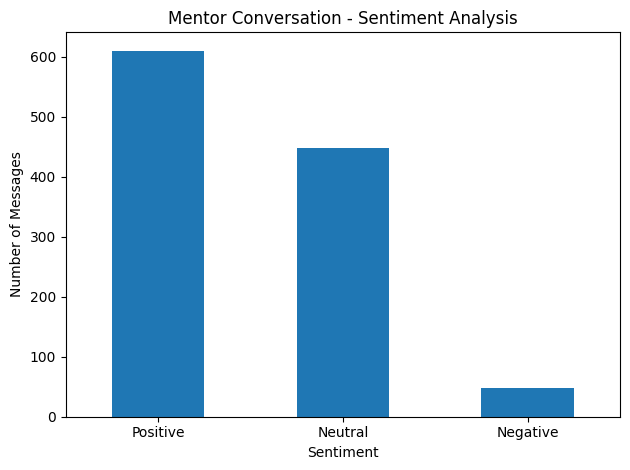

In [17]:
# 7. Visualize sentiment distribution
sentiment_df["Sentiment"].value_counts().plot(
    kind="bar",
    title="Mentor Conversation - Sentiment Analysis",
    xlabel="Sentiment",
    ylabel="Number of Messages"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [18]:
import os

In [19]:
# 8. Save results to CSV and Excel
file_name = "My mentor conversation chat sentiment analysis"

sentiment_df.to_csv(
    file_name + ".csv",
    index=False,
    encoding="utf-8-sig"
)

sentiment_df.to_excel(
    file_name + ".xlsx",
    index=False
)

print("Sentiment Analysis completed!")
print("CSV and Excel files saved in:", __import__("os").getcwd())


Sentiment Analysis completed!
CSV and Excel files saved in: C:\HOPE AI\AI Course Tamil\Week-13-Natural Language Process\Counter Vector
